# 04 · K-Means Clustering

K-Means partitions **every** point into exactly `K` clusters by minimising the
within-cluster sum of squared distances (inertia). Consequences:

- there is no noise category — isolated block groups are still forced into the
  nearest cluster;
- `K` must be chosen in advance;
- clusters are convex Voronoi regions, so elongated or ring-shaped structures
  cannot be represented.

We use the Elbow Method plus silhouette scores to pick `K`, then compare the
same feature matrices used for DBSCAN.

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Avoid a noisy joblib CPU-detection warning on Windows.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root (the folder that contains src/) so the notebooks run
# whether Jupyter was started from notebooks/ or from the project root.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import preprocessing as pp
import clustering as cl
import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

print("Project root:", ROOT)
print("Dataset:", pp.DATA_PATH)

Project root: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering
Dataset: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\data\housing.csv


## Part A — K-Means on geographical features (2-D)

The elbow is the point where extra clusters stop producing a large drop in
inertia. Silhouette measures how much closer points are to their own cluster than
to the next-closest one.

In [2]:
ds_geo = pp.prepare_dataset("geo")

km_results_geo = cl.kmeans_experiments(ds_geo.X, range(2, 13), sample_size=8000)
km_results_geo.to_csv(pp.OUTPUT_DIR / "kmeans_geo_grid.csv", index=False)

elbow_geo = cl.elbow_k(km_results_geo)
best_sil_geo = cl.best_k_by_silhouette(km_results_geo)
best_row = km_results_geo.loc[km_results_geo["silhouette"].idxmax()]

print(f"Elbow K: {elbow_geo}")
print(f"Best silhouette: K={best_sil_geo} (silhouette={best_row['silhouette']:.3f})")

km_results_geo.round(3)

Elbow K: 6
Best silhouette: K=2 (silhouette=0.754)


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,runtime_s
0,2,6240.810,0.754,0.328,115872.608,0.090
1,3,4254.552,0.645,0.593,89797.899,0.041
2,4,3301.756,0.606,0.603,79121.955,0.050
3,5,2435.588,0.580,0.708,82275.578,0.076
4,6,1869.255,0.570,0.689,87008.189,0.064
5,7,1599.057,0.572,0.713,85336.155,0.077
6,8,1416.422,0.490,0.778,82953.432,0.095
7,9,1254.972,0.492,0.730,82248.762,0.116
8,10,1101.016,0.502,0.746,83649.299,0.123
9,11,1044.083,0.501,0.737,79504.116,0.123


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_elbow_geo.png


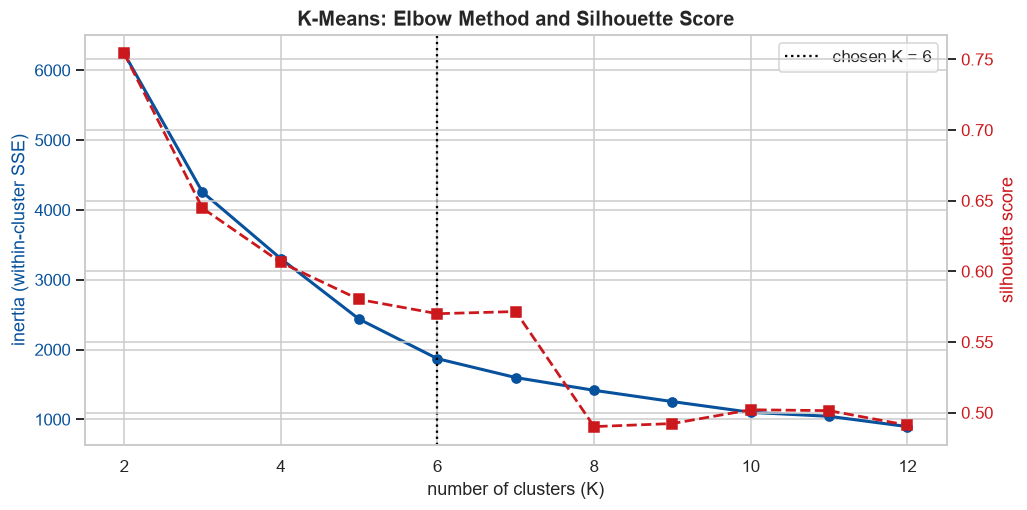

In [3]:
fig, path = viz.plot_elbow_curve(km_results_geo, chosen_k=6, name="kmeans_elbow_geo")
print("saved:", path)
plt.show()

### Choosing K = 6

The inertia curve bends at **K = 6**: the drop from K=5 to K=6 is 566, but from
K=6 to K=7 it is 270, and improvement continues to shrink afterwards.

Silhouette is maximised at **K = 2 (0.754)**, but K=2 only splits California into
a northern and a southern half — useless for hotspot analysis. At K=6 the
silhouette is still **0.570**, and the six regions are geographically coherent.
That is a documented judgment call: the elbow and interpretability beat the
metric optimum at the trivial K.

In [4]:
K_GEO = 6
km_geo = cl.run_kmeans(ds_geo.X, K_GEO)
labels_km = km_geo.labels_

print(cl.label_summary(labels_km))
print(f"final inertia: {km_geo.inertia_:,.1f}")

metrics_km = cl.evaluate_clustering(ds_geo.X, labels_km, sample_size=8000)
print("Metrics:", {key: round(value, 3) if isinstance(value, float) else value
                   for key, value in metrics_km.items()})

profile_km = cl.cluster_profile(ds_geo.df, labels_km)

results_km = ds_geo.df.copy()
results_km["kmeans_cluster"] = labels_km
results_km.to_csv(pp.OUTPUT_DIR / "kmeans_geo_labels.csv", index=False)
profile_km.to_csv(pp.OUTPUT_DIR / "kmeans_geo_profile.csv")
print("saved labels and profile to", pp.OUTPUT_DIR)

{'n_clusters': 6, 'n_noise': 0, 'noise_pct': 0.0, 'n_clustered_points': 20640}
final inertia: 1,869.3


Metrics: {'n_clusters': 6, 'n_noise': 0, 'noise_pct': 0.0, 'n_clustered_points': 20640, 'silhouette': 0.57, 'davies_bouldin': 0.689, 'calinski_harabasz': 87008.189, 'silhouette_sample_size': 8000}


saved labels and profile to D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs


In [5]:
profile_km[["n_points", "share_pct", "mean_house_value", "mean_income",
            "mean_latitude", "mean_longitude",
            "dominant_ocean_proximity"]].sort_values(
    "mean_house_value", ascending=False).round(2)

,n_points,share_pct,mean_house_value,mean_income,mean_latitude,mean_longitude,dominant_ocean_proximity
cluster,,,,,,,
1,4827,23.39,262986.42,4.47,37.67,-122.17,NEAR BAY
0,8839,42.82,230302.43,4.09,34.01,-118.12,<1H OCEAN
4,2216,10.74,177335.58,3.58,33.08,-116.94,NEAR OCEAN
3,2328,11.28,126066.45,3.14,38.40,-121.14,INLAND
2,1744,8.45,123074.50,3.02,35.96,-119.68,INLAND
5,686,3.32,92310.78,2.48,40.18,-122.76,INLAND


## Visualising the K-Means regions

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_clusters.png


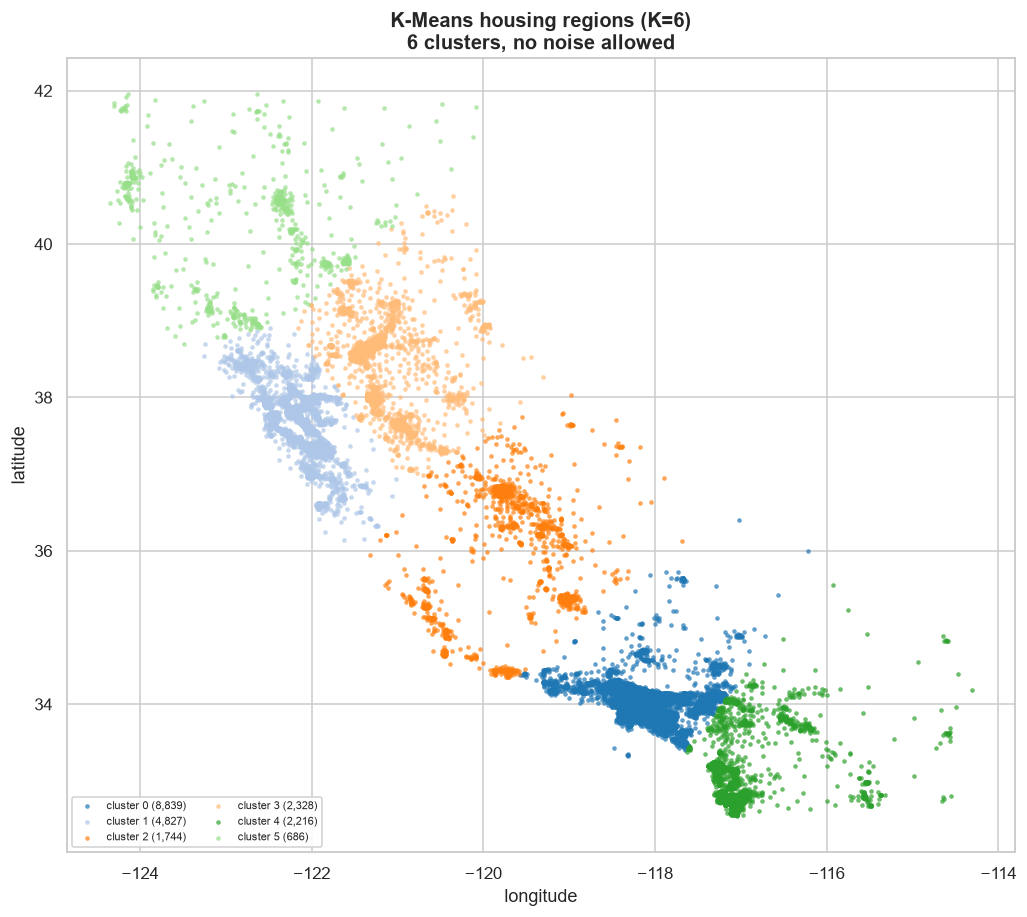

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_avg_value.png


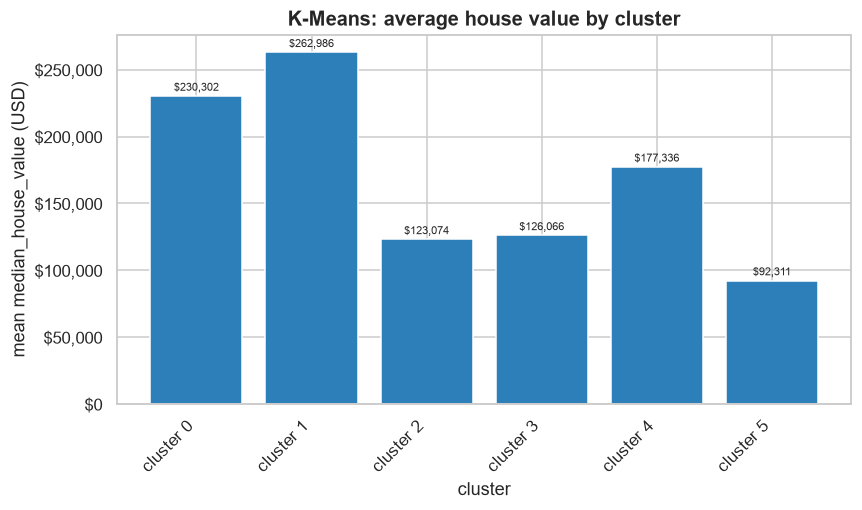

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_cluster_sizes.png


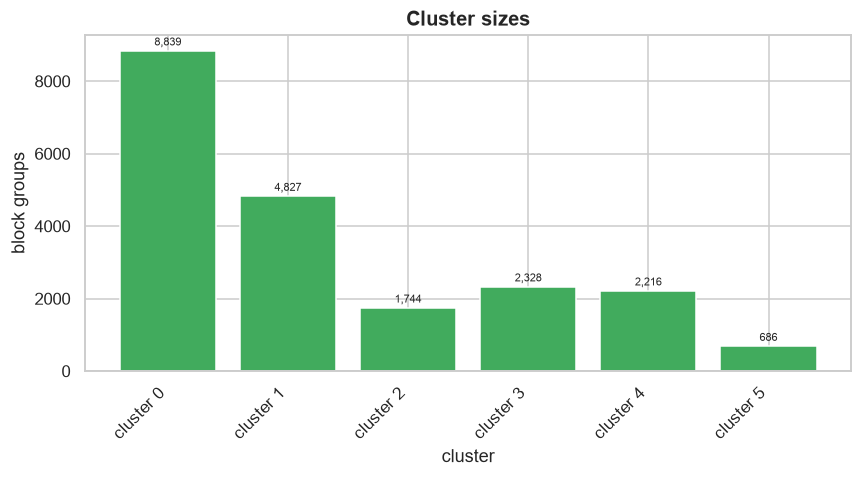

In [6]:
fig, path = viz.plot_kmeans_clusters(
    ds_geo.df, labels_km, title="K-Means housing regions (K=6)",
    name="kmeans_clusters",
)
print("saved:", path)
plt.show()

fig, path = viz.plot_avg_value_by_cluster(
    profile_km, title="K-Means: average house value by cluster",
    name="kmeans_avg_value",
)
print("saved:", path)
plt.show()

fig, path = viz.plot_cluster_sizes(profile_km, name="kmeans_cluster_sizes")
print("saved:", path)
plt.show()

In [7]:
map_path = viz.build_cluster_map(
    ds_geo.df, labels_km,
    title="K-Means housing regions (K=6)",
    filename="kmeans_clusters.html",
)
plotly_path = viz.save_plotly_cluster_scatter(
    ds_geo.df, labels_km,
    title="K-Means housing regions (interactive)",
    filename="kmeans_clusters_interactive.html",
    algorithm="K-Means",
)
scatter_path = viz.save_plotly_cluster_scatter_2d(
    ds_geo.df, labels_km,
    title="K-Means clusters in feature space (income vs value)",
    filename="kmeans_clusters_scatter.html",
)

print("folium map:", map_path)
print("plotly map:", plotly_path)
print("plotly scatter:", scatter_path)

folium map: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\maps\kmeans_clusters.html
plotly map: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_clusters_interactive.html
plotly scatter: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_clusters_scatter.html


In [8]:
expensive = []
for cluster in range(K_GEO):
    values = ds_geo.df.loc[labels_km == cluster, "median_house_value"]
    expensive.append({
        "cluster": cluster,
        "n_block_groups": len(values),
        "mean_value": values.mean(),
        "pct_ge_400k": (values >= 400_000).mean() * 100,
        "pct_at_cap": (values >= 500_001).mean() * 100,
    })

pd.DataFrame(expensive).round(2)

,cluster,n_block_groups,mean_value,pct_ge_400k,pct_at_cap
0,0,8839,230302.43,10.66,6.14
1,1,4827,262986.42,14.05,7.17
2,2,1744,123074.50,2.24,1.38
3,3,2328,126066.45,0.34,0.04
4,4,2216,177335.58,4.69,2.30
5,5,686,92310.78,0.00,0.00


In [9]:
print("cluster-level income/value correlation:",
      round(profile_km["mean_income"].corr(profile_km["mean_house_value"]), 3))

cluster-level income/value correlation: 0.991


## Interpreting the K-Means regions

| cluster | region | block groups | mean value | mean income | share ≥ \$400k |
|---|---|---:|---:|---:|---:|
| 1 | San Francisco Bay Area (37.67, −122.17) | 4,827 | \$262,986 | 4.47 | **14.0%** |
| 0 | Los Angeles / southern coast (34.01, −118.12) | 8,839 | \$230,302 | 4.09 | **10.7%** |
| 4 | San Diego (33.08, −116.94) | 2,216 | \$177,336 | 3.58 | 4.7% |
| 3 | Sacramento / north (38.40, −121.14) | 2,328 | \$126,066 | 3.14 | 0.3% |
| 2 | Central Valley south (35.96, −119.68) | 1,744 | \$123,075 | 3.02 | 2.2% |
| 5 | Far north / rural (40.18, −122.76) | 686 | \$92,311 | 2.48 | 0.0% |

Expensive housing is unmistakably concentrated: Bay Area (14.0%) and Los Angeles
(10.7%) contain most of the ≥ \$400k block groups, while Sacramento (0.3%) and
the far north (0.0%) contain almost none. The overall share is 8.58%.

Mean income and mean house value across the six clusters correlate at
**r ≈ 0.99** — even more strongly than across the 22 DBSCAN clusters, because
K-Means regions are larger and smoother.

## Part B — K-Means on the same 11-feature matrix as DBSCAN

For a like-for-like comparison, K-Means is also fitted to the exact matrix used
in notebook 03 Part A, over the same K range (2–12) used in Part A. The inertia
curve bends at **K = 5** here; the elbow is read together with the table and the
silhouette rather than trusted as a single number.

In [10]:
ds_combined = pp.prepare_dataset("geo_housing")

km_results_comb = cl.kmeans_experiments(ds_combined.X, range(2, 13), sample_size=8000)
km_results_comb.to_csv(pp.OUTPUT_DIR / "kmeans_combined_grid.csv", index=False)

print(f"Elbow K: {cl.elbow_k(km_results_comb)}")
print(f"Best silhouette K: {cl.best_k_by_silhouette(km_results_comb)}")
km_results_comb.round(3)

Elbow K: 5
Best silhouette K: 2


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,runtime_s
0,2,183245.467,0.353,1.349,4932.356,0.097
1,3,149962.783,0.225,1.522,5303.458,0.090
2,4,129872.913,0.212,1.380,5146.420,0.143
3,5,118143.995,0.214,1.297,4754.937,0.149
4,6,108356.751,0.200,1.360,4520.099,0.207
5,7,101302.536,0.180,1.451,4268.313,0.285
6,8,95327.383,0.182,1.433,4072.437,0.315
7,9,90780.776,0.180,1.441,3870.820,0.261
8,10,86789.905,0.177,1.432,3704.176,0.303
9,11,83328.136,0.182,1.410,3557.786,0.510


In [11]:
K_COMB = cl.elbow_k(km_results_comb)
km_combined = cl.run_kmeans(ds_combined.X, K_COMB)
profile_km_comb = cl.cluster_profile(ds_combined.df, km_combined.labels_)

print(f"K = {K_COMB}")
print(cl.label_summary(km_combined.labels_))
profile_km_comb[["n_points", "share_pct", "mean_house_value", "mean_income",
                 "mean_latitude", "mean_longitude",
                 "dominant_ocean_proximity"]].round(2)

K = 5
{'n_clusters': 5, 'n_noise': 0, 'noise_pct': 0.0, 'n_clustered_points': 20640}


,n_points,share_pct,mean_house_value,mean_income,mean_latitude,mean_longitude,dominant_ocean_proximity
cluster,,,,,,,
0,6686,32.39,172409.80,2.83,34.06,-118.12,<1H OCEAN
1,2477,12.00,212510.01,3.90,35.33,-119.28,<1H OCEAN
2,280,1.36,215435.74,4.48,35.06,-118.84,INLAND
3,6644,32.19,182040.52,3.40,38.06,-121.79,INLAND
4,4553,22.06,290047.36,6.02,34.61,-118.67,<1H OCEAN


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_clusters_combined.png


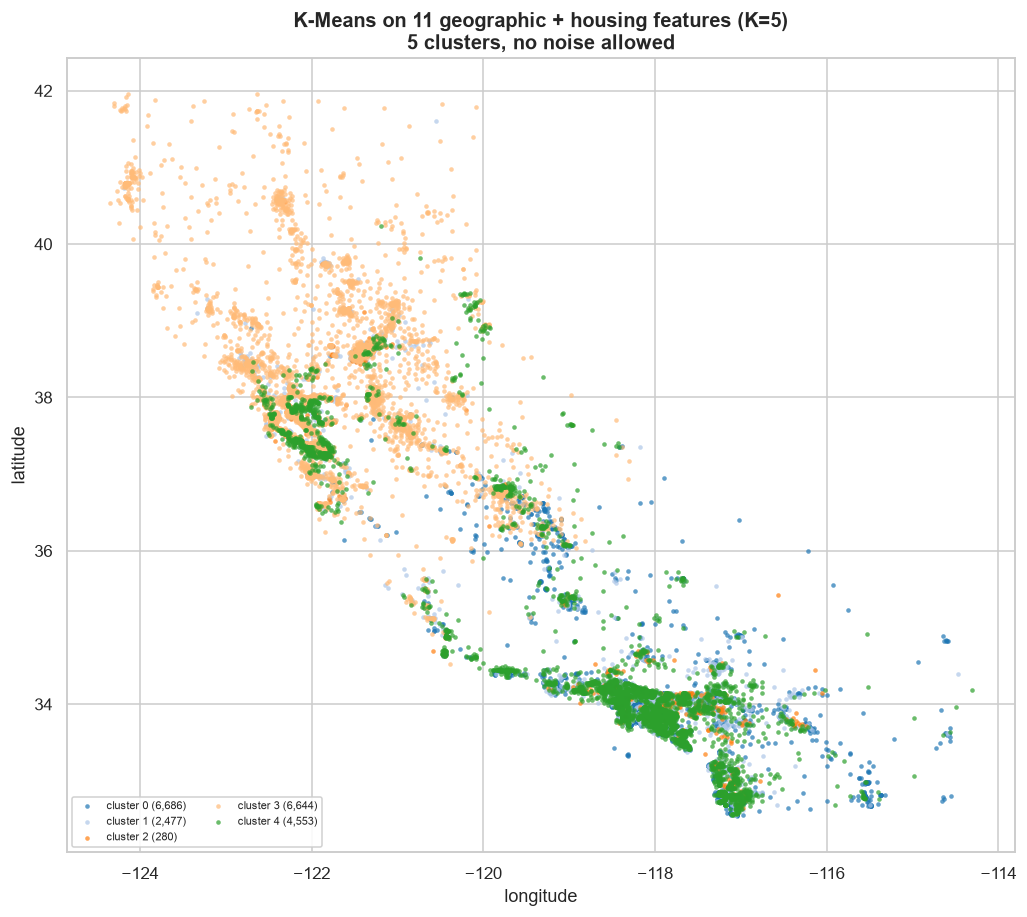

{'n_clusters': 5, 'n_noise': 0, 'noise_pct': 0.0, 'n_clustered_points': 20640, 'silhouette': 0.214, 'davies_bouldin': 1.297, 'calinski_harabasz': 4754.937, 'silhouette_sample_size': 8000}


In [12]:
fig, path = viz.plot_kmeans_clusters(
    ds_combined.df, km_combined.labels_,
    title=f"K-Means on 11 geographic + housing features (K={K_COMB})",
    name="kmeans_clusters_combined",
)
print("saved:", path)
plt.show()

combined_km_metrics = cl.evaluate_clustering(ds_combined.X, km_combined.labels_,
                                             sample_size=8000)
print({key: round(value, 3) if isinstance(value, float) else value
       for key, value in combined_km_metrics.items()})

profile_km_comb.to_csv(pp.OUTPUT_DIR / "kmeans_combined_profile.csv")

### Part B finding

K-Means still produces a complete partition of the 11-D space. Unlike DBSCAN it
does not break down: every block group is assigned, and the five clusters differ
in income and housing profile. The highest-income cluster (4,553 block groups,
mean income 6.02, mean value \$290,047) is a mix of expensive coastal and inland
areas, so these are **attribute clusters rather than geographic regions**.

The combined-space silhouette is only **0.214**, much lower than the 0.570
achieved in 2-D. Adding nine attribute dimensions makes the clusters less
well-separated, even though K-Means technically succeeds.

## K-Means findings

- Geo matrix, K=6: silhouette **0.570**, Davies–Bouldin **0.689**,
  Calinski–Harabasz **87,008**, runtime **≈0.2 s**, 0% noise by construction.
- Six interpretable regions; the Bay Area and Los Angeles dominate expensive
  housing.
- Combined 11-D matrix, K=5: silhouette drops to **0.214**; clusters become
  attribute-driven and less geographically coherent.
- K-Means is fast, deterministic with a fixed seed, and always returns a full
  partition — but it cannot express "this place belongs to no cluster".